# 02. Analysis and results

**From Augmentation to Replacement: Competing Frames of AI's Labour Impact
across News, Public, and Insider Discourse, 2022–2026**
Meshaal Kirmani · COMM424DA · Supervisor: Dr Chico Camargo

---

This notebook reproduces **every table, figure and quoted number** in Sections 3
and 4 of the report, directly from the frozen data in `data/`.

| Report artefact | Section here |
|---|---|
| Table 1, corpus by ecosystem | 1 |
| Table 2 and Figure 2, human vs model agreement | 2 |
| Table 3, three-way agreement | 2 |
| Figure 3, frame inventory (RQ1) | 3 |
| Table 4 and Figure 4, Entman signatures (RQ2) | 4 |
| Table 5 and Figure 5, ecosystem variation (RQ3) | 5 |
| Table 6 and Figure 6, temporal dynamics (RQ4) | 6 |
| Figure 7, unsupervised triangulation | 7 |
| Reproduction check, asserts all published values | 8 |

Statistical helpers live in `src/analysis.py` so each test is computed
identically wherever it appears. Figures are written to `figures/`.

In [1]:
import sys, json, warnings
from pathlib import Path
from itertools import combinations
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, kruskal
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf

import analysis as A
A.apply_report_style()
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

df = A.load_coded()          # 1,800 coded items
nt = A.analytic(df)          # 1,205 non-tangential
RESULTS = {}                 # collected for the final reproduction check

print(f"coded sample   : {len(df):,}")
print(f"analytic sample: {len(nt):,}")
RESULTS["n_coded"], RESULTS["n_analytic"] = len(df), len(nt)

coded sample   : 1,800
analytic sample: 1,205


## 1. The corpus (Table 1)

All three ecosystems clear the pre-registered ≥500-item success criterion. The
coded sample is balanced by design and is therefore a very different fraction of
each corpus: close to a census for Hacker News, a 2.2% probability sample for
Reddit.
That difference in precision is why confidence intervals accompany every
proportion in this notebook.

In [2]:
clean = A.load_clean()
funnel = json.loads((ROOT / "data/meta/funnel.json").read_text())

tab1 = pd.DataFrame({
    "Raw retrieved": {s: funnel["per_source"][s]["retrieved"] for s in A.SOURCES},
    "Clean corpus":  {s: funnel["per_source"][s]["clean"] for s in A.SOURCES},
    "Coded":         df.source.value_counts().to_dict(),
})
tab1["Sample % of corpus"] = (tab1["Coded"] / tab1["Clean corpus"] * 100).round(1)
tab1.index = [A.SRC_SHORT[s] for s in tab1.index]
tab1.loc["TOTAL"] = [tab1["Raw retrieved"].sum(), tab1["Clean corpus"].sum(),
                     tab1["Coded"].sum(), np.nan]
display(tab1)

RESULTS["n_clean"] = int(tab1.loc["TOTAL", "Clean corpus"])
RESULTS["n_raw"] = int(tab1.loc["TOTAL", "Raw retrieved"])

,Raw retrieved,Clean corpus,Coded,Sample % of corpus
Hacker News,9393.0,951.0,600.0,63.1
Reddit,116977.0,27554.0,600.0,2.2
MediaCloud,201900.0,12230.0,600.0,4.9
TOTAL,328270.0,40735.0,1800.0,NaN


## 2. Validation (Tables 2 and 3, Figure 2)

The gate was fixed in the proposal before any coding: κ ≥ 0.60 on at least three
of four Entman functions. Both κ and raw agreement are reported, because for
treatment recommendation the two tell different stories.

In [3]:
m = A.load_human()
rows = []
for c in A.CODE_COLS:
    a, b = m[f"{c}_h"], m[f"{c}_m"]
    labels = sorted(set(a) | set(b))
    k = cohen_kappa_score(a, b, labels=labels)
    agr = (a == b).mean()
    # kappa on the subset where neither coder said TANGENTIAL: the frame
    # distinctions the study actually rests on
    sub = m[(m.coarse_frame_h != "TANGENTIAL") & (m.coarse_frame_m != "TANGENTIAL")]
    ka, kb = sub[f"{c}_h"], sub[f"{c}_m"]
    k_sub = cohen_kappa_score(ka, kb, labels=sorted(set(ka) | set(kb)))
    rows.append({"Variable": c, "kappa (all 300)": round(k, 3),
                 "kappa (excl. tangential)": round(k_sub, 3),
                 "Raw agreement": round(agr, 3), "gap": round(agr - k, 3)})
tab2 = pd.DataFrame(rows).set_index("Variable")
display(tab2)

RESULTS["kappa_frame"] = tab2.loc["coarse_frame", "kappa (all 300)"]
RESULTS["kappa_treatment"] = tab2.loc["treatment", "kappa (all 300)"]
RESULTS["agree_treatment"] = tab2.loc["treatment", "Raw agreement"]
RESULTS["n_validation"] = len(m)
RESULTS["n_functions_passing"] = int(
    (tab2.loc[["problem", "cause", "moral", "treatment"], "kappa (all 300)"] >= 0.60).sum())

print(f"\nfunctions clearing 0.60: {RESULTS['n_functions_passing']}/4  -> "
      f"{'PASS' if RESULTS['n_functions_passing'] >= 3 else 'FAIL'}")
print(f"largest agreement-kappa gap: {tab2.gap.idxmax()} ({tab2.gap.max():.3f})")
print(f"highest raw agreement:       {tab2['Raw agreement'].idxmax()} "
      f"({tab2['Raw agreement'].max():.3f})")

,kappa (all 300),kappa (excl. tangential),Raw agreement,gap
Variable,,,,
coarse_frame,0.797,0.765,0.860,0.063
problem,0.834,0.860,0.887,0.053
cause,0.792,0.749,0.857,0.065
moral,0.803,0.794,0.853,0.051
treatment,0.591,0.641,0.877,0.286



functions clearing 0.60: 3/4  -> PASS
largest agreement-kappa gap: treatment (0.286)
highest raw agreement:       problem (0.887)


Treatment recommendation is the one function below the gate, and the gap
column is the diagnostic: 0.286 against 0.050–0.065 for every other variable.
Roughly four-fifths of items recommend nothing, so chance agreement is high and
the correction severe. Note that treatment's raw agreement is *second* highest,
not the highest, since problem definition edges it, but its chance correction is
four to six times larger than any other. This is the kappa paradox.

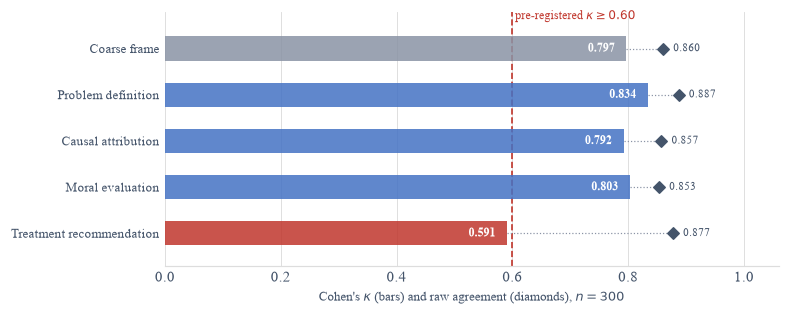

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
order = list(reversed(A.CODE_COLS))
lab = {"coarse_frame": "Coarse frame", "problem": "Problem definition",
       "cause": "Causal attribution", "moral": "Moral evaluation",
       "treatment": "Treatment recommendation"}
y = np.arange(len(order))
kap = [tab2.loc[c, "kappa (all 300)"] for c in order]
agr = [tab2.loc[c, "Raw agreement"] for c in order]
cols = [A.MUTED if c == "coarse_frame" else (A.RED if k < .60 else A.BLUE)
        for c, k in zip(order, kap)]
ax.barh(y, kap, height=.52, color=cols, alpha=.85, zorder=3)
for i, (k, a_) in enumerate(zip(kap, agr)):
    ax.plot([k, a_], [i, i], color=A.MUTED, lw=.8, ls=":", zorder=3.5)
    ax.text(k - .02, i, f"{k:.3f}", va="center", ha="right", fontsize=8,
            color="white", fontweight="bold", zorder=5)
    ax.text(a_ + .018, i, f"{a_:.3f}", va="center", fontsize=7.5, color=A.NAVY)
ax.scatter(agr, y, marker="D", s=28, color=A.NAVY, zorder=4)
ax.axvline(.60, color=A.RED, ls="--", lw=1.1)
ax.text(.605, len(order) - .45, "pre-registered $\\kappa \\geq 0.60$",
        fontsize=8, color=A.RED, va="bottom")
ax.set_yticks(y); ax.set_yticklabels([lab[c] for c in order], fontsize=8.5)
ax.set_xlim(0, 1.06); ax.set_ylim(-.7, len(order) - .2)
ax.set_xlabel("Cohen's $\\kappa$ (bars) and raw agreement (diamonds), $n=300$", fontsize=8.5)
A.despine(ax, grid_axis="x")
fig.savefig(FIG / "fig2_kappa.pdf", bbox_inches="tight"); plt.show()

In [5]:
# Table 3: three-way agreement on the coarse frame.
# GABRIEL writes one row per (item, variable) with the winning label in `code`
# and the full 0-100 score vector in `scores`; the coarse frame is selected out.
gab = pd.DataFrame([json.loads(l) for l in
                    open(ROOT / "data/coding/gabriel_codes_gold300.jsonl")])
gab = gab[gab.variable == "coarse_frame"].copy()
gab["coarse_frame_g"] = gab.code.astype(str).str.strip().str.upper()
three = m[["id", "coarse_frame_h", "coarse_frame_m"]].merge(
    gab[["id", "coarse_frame_g"]], on="id")
print(f"three-way comparison on {len(three)} items (model: {gab.model.iloc[0]})")

def kap(a, b):
    return cohen_kappa_score(a, b, labels=sorted(set(a) | set(b)))

tab3 = pd.DataFrame([
    {"Comparison": "Human vs Claude",
     "kappa": round(kap(three.coarse_frame_h, three.coarse_frame_m), 3),
     "Raw": round((three.coarse_frame_h == three.coarse_frame_m).mean(), 3)},
    {"Comparison": "Claude vs GABRIEL",
     "kappa": round(kap(three.coarse_frame_m, three.coarse_frame_g), 3),
     "Raw": round((three.coarse_frame_m == three.coarse_frame_g).mean(), 3)},
    {"Comparison": "Human vs GABRIEL",
     "kappa": round(kap(three.coarse_frame_h, three.coarse_frame_g), 3),
     "Raw": round((three.coarse_frame_h == three.coarse_frame_g).mean(), 3)},
]).set_index("Comparison")
display(tab3)

print("frame counts by coder (n = %d):" % len(three))
print(pd.DataFrame({
    "human":   three.coarse_frame_h.value_counts(),
    "Claude":  three.coarse_frame_m.value_counts(),
    "GABRIEL": three.coarse_frame_g.value_counts()}).fillna(0).astype(int).to_string())

three-way comparison on 300 items (model: gpt-4o)


,kappa,Raw
Comparison,,
Human vs Claude,0.797,0.860
Claude vs GABRIEL,0.503,0.670
Human vs GABRIEL,0.425,0.607


frame counts by coder (n = 300):
                human  Claude  GABRIEL
AUGMENTATION       38      32       56
MIXED              13       3        0
REPLACEMENT       123     129      121
TANGENTIAL         94     106      121
TRANSFORMATION     32      30        2


GABRIEL's weaker agreement is **architectural, not random**. It scores each
category independently and takes the maximum, a formulation that cannot express
a judgement about relative balance, so it returns almost no MIXED or
TRANSFORMATION. Convergence is strong precisely where frames carry unambiguous
lexical markers: all three coders identify replacement at similar rates. The
cross-check therefore supports the primary coding where frames are lexically
marked, and *identifies* rather than merely fails on frames requiring a
comparative judgement.

## 3. RQ1: the frame inventory (Figure 3)

In [6]:
counts = nt.coarse_frame.value_counts().reindex(A.FRAME_ORDER)
share = counts / len(nt) * 100
lo, hi = A.wilson(counts, len(nt))

rq1 = pd.DataFrame({"n": counts, "%": share.round(1),
                    "CI low": (lo * 100).round(1), "CI high": (hi * 100).round(1)})
display(rq1)

tang = df.groupby("source").coarse_frame.apply(lambda s: (s == "TANGENTIAL").mean() * 100)
print("tangential (off-topic) rate by ecosystem:")
for s in A.SRC_ORDER:
    print(f"  {A.SRC_SHORT[s]:12s} {tang[s]:5.1f}%")
print("\nmodal frame per ecosystem:",
      {A.SRC_SHORT[k]: v for k, v in
       nt.groupby('source').coarse_frame.apply(lambda s: s.value_counts().idxmax()).items()})

for f in A.FRAME_ORDER:
    RESULTS[f"rq1_{f.lower()}"] = round(share[f], 1)
RESULTS["tangential_hn"] = round(tang["hackernews"], 1)

,n,%,CI low,CI high
coarse_frame,,,,
REPLACEMENT,738,61.2,58.5,64.0
AUGMENTATION,219,18.2,16.1,20.5
TRANSFORMATION,216,17.9,15.9,20.2
MIXED,32,2.7,1.9,3.7


tangential (off-topic) rate by ecosystem:
  MediaCloud    25.7%
  Reddit        27.7%
  Hacker News   45.8%

modal frame per ecosystem: {'Hacker News': 'REPLACEMENT', 'MediaCloud': 'REPLACEMENT', 'Reddit': 'REPLACEMENT'}


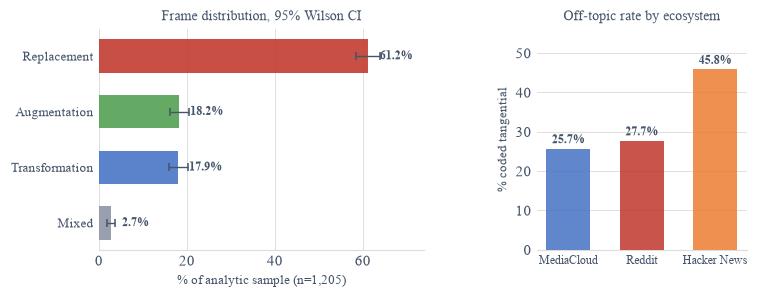

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 2.6),
                             gridspec_kw={"width_ratios": [1.55, 1], "wspace": .42})
yv = np.arange(len(A.FRAME_ORDER))[::-1]
a1.barh(yv, share.values, height=.6, color=[A.FRAME_COL[f] for f in A.FRAME_ORDER],
        alpha=.88, zorder=3)
a1.errorbar(share.values, yv, xerr=[share.values - lo * 100, hi * 100 - share.values],
            fmt="none", ecolor=A.NAVY, elinewidth=.9, capsize=2.5, zorder=4)
for i, f in enumerate(A.FRAME_ORDER):
    a1.text(share[f] + 2.6, yv[i], f"{share[f]:.1f}%", va="center", fontsize=8,
            fontweight="bold", color=A.NAVY)
a1.set_yticks(yv); a1.set_yticklabels([A.FRAME_LAB[f] for f in A.FRAME_ORDER], fontsize=8.5)
a1.set_xlim(0, 74); a1.set_xlabel(f"% of analytic sample (n={len(nt):,})", fontsize=8.5)
a1.set_title("Frame distribution, 95% Wilson CI", fontsize=9, pad=6)
A.despine(a1, grid_axis="x")

tv = [tang[s] for s in A.SRC_ORDER]
a2.bar(range(3), tv, color=[A.SRC_COL[s] for s in A.SRC_ORDER], alpha=.85, width=.6, zorder=3)
for i, v in enumerate(tv):
    a2.text(i, v + 1.4, f"{v:.1f}%", ha="center", fontsize=8, fontweight="bold", color=A.NAVY)
a2.set_xticks(range(3)); a2.set_xticklabels([A.SRC_SHORT[s] for s in A.SRC_ORDER], fontsize=8)
a2.set_ylim(0, 56); a2.set_ylabel("% coded tangential", fontsize=8.5)
a2.set_title("Off-topic rate by ecosystem", fontsize=9, pad=6)
A.despine(a2)
fig.savefig(FIG / "fig3_rq1_frames.pdf", bbox_inches="tight"); plt.show()

Mixed framing at 2.7% sits far below the codebook's 15% warning ceiling,
indicating the dominance rule (R1) is working: coders are choosing rather than
retreating to a safe middle category.

The tangential rate varies by ecosystem, from 45.8% on Hacker News to around 26
to 28% elsewhere. It describes how precise the retrieval was, not how noisy the
coding was.
An item enters the corpus by containing an AI term and a labour term; Hacker News
satisfies that far more often without characterising the relation between them.
Rule R0 excludes those by design.

## 4. RQ2: Entman-function signatures (Table 4, Figure 4)

In [8]:
rows, resid = [], {}
for f in A.FUNCTIONS:
    ct = pd.crosstab(nt.coarse_frame, nt[f]).reindex(A.FRAME_ORDER).fillna(0)
    r = A.cramers_v(ct)
    r["function"] = A.FUNC_LAB[f]
    r["p_perm"] = A.perm_chi2(ct) if r["cells_lt5"] else np.nan
    rows.append(r); resid[f] = A.std_residuals(ct)

tab4 = pd.DataFrame(rows).set_index("function")[
    ["chi2", "dof", "V", "p", "cells_lt5", "cells", "p_perm"]].round(
    {"chi2": 1, "V": 3, "p_perm": 4})
display(tab4)
RESULTS["rq2_V_problem"] = round(tab4.loc["Problem definition", "V"], 3)
RESULTS["rq2_V_cause"] = round(tab4.loc["Causal attribution", "V"], 3)

,chi2,dof,V,p,cells_lt5,cells,p_perm
function,,,,,,,
Problem definition,1217.4,12,0.580,3.039086e-253,3,20,0.0002
Moral evaluation,565.5,9,0.396,5.340713e-116,1,16,0.0002
Treatment recommendation,194.4,12,0.232,4.716211e-35,4,20,0.0002
Causal attribution,135.1,12,0.193,5.929036e-23,5,20,0.0002


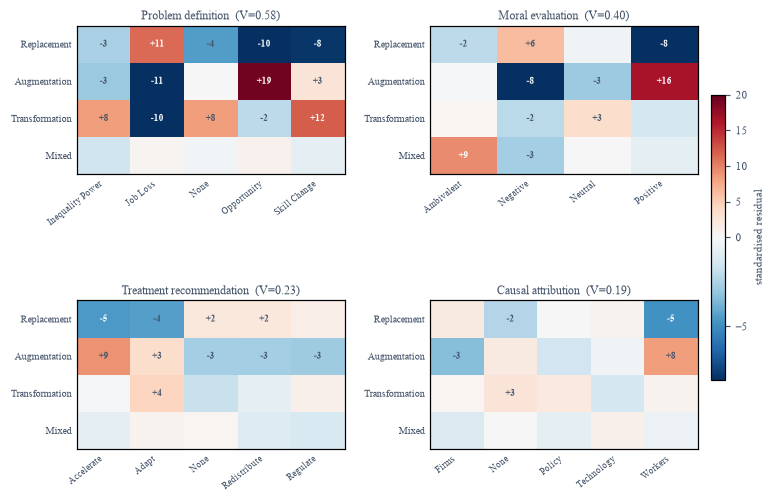

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(7.6, 5.0),
                         gridspec_kw={"hspace": .85, "wspace": .32})
from matplotlib.colors import TwoSlopeNorm
norm = TwoSlopeNorm(vcenter=0, vmin=-8, vmax=20)
for ax, f in zip(axes.ravel(), A.FUNCTIONS):
    R = resid[f]
    im = ax.imshow(R.values, cmap="RdBu_r", norm=norm, aspect="auto")
    ax.set_xticks(range(R.shape[1]))
    ax.set_xticklabels([c.replace("_", " ").title() for c in R.columns],
                       fontsize=6, rotation=38, ha="right")
    ax.set_yticks(range(R.shape[0]))
    ax.set_yticklabels([A.FRAME_LAB[i] for i in R.index], fontsize=6.6)
    ax.set_title(f"{A.FUNC_LAB[f]}  (V={tab4.loc[A.FUNC_LAB[f],'V']:.2f})", fontsize=8, pad=4)
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            z = R.values[i, j]
            if abs(z) >= 2:
                ax.text(j, i, f"{z:+.0f}", ha="center", va="center", fontsize=5.8,
                        color="white" if (z <= -4.5 or z >= 9) else A.NAVY,
                        fontweight="bold")
    ax.tick_params(length=0)
cb = fig.colorbar(im, ax=axes, fraction=.022, pad=.02)
cb.set_label("standardised residual", fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(FIG / "fig4_rq2_residuals.pdf", bbox_inches="tight"); plt.show()

In [10]:
print("strongest cells per function (standardised residuals):")
for f in A.FUNCTIONS:
    top = resid[f].stack().sort_values(ascending=False).head(3)
    print(f"  {A.FUNC_LAB[f]:24s} " +
          " | ".join(f"{A.FRAME_LAB.get(i[0], i[0])}->{i[1]} z={v:+.1f}" for i, v in top.items()))

print("\nreplacement's profile, as row percentages within the frame:")
for f in ("treatment", "cause"):
    ct = pd.crosstab(nt.coarse_frame, nt[f])
    pct = (ct.T / ct.sum(1)).T * 100
    print(f"  {f:10s} " + "  ".join(f"{c}={pct.loc['REPLACEMENT', c]:.1f}%"
                                    for c in pct.columns))
RESULTS["repl_treatment_none"] = round(
    (nt[nt.coarse_frame == "REPLACEMENT"].treatment == "NONE").mean() * 100, 1)
RESULTS["repl_cause_none"] = round(
    (nt[nt.coarse_frame == "REPLACEMENT"].cause == "NONE").mean() * 100, 1)

strongest cells per function (standardised residuals):
  Problem definition       Augmentation->OPPORTUNITY z=+19.4 | Transformation->SKILL_CHANGE z=+12.0 | Replacement->JOB_LOSS z=+11.4
  Moral evaluation         Augmentation->POSITIVE z=+16.4 | Mixed->AMBIVALENT z=+9.4 | Replacement->NEGATIVE z=+6.1
  Treatment recommendation Augmentation->ACCELERATE z=+8.9 | Transformation->ADAPT z=+4.4 | Augmentation->ADAPT z=+3.5
  Causal attribution       Augmentation->WORKERS z=+8.3 | Transformation->NONE z=+2.6 | Transformation->POLICY z=+1.9

replacement's profile, as row percentages within the frame:
  treatment  ACCELERATE=2.0%  ADAPT=6.1%  NONE=81.6%  REDISTRIBUTE=4.7%  REGULATE=5.6%
  cause      FIRMS=29.1%  NONE=1.8%  POLICY=1.9%  TECHNOLOGY=66.3%  WORKERS=0.9%


The absence here is specific. Replacement defines the problem as job loss
(z = +11.4) and evaluates it negatively (z = +6.1), but beyond that its signature
is almost entirely *negative*: significantly under-represented in recommending
acceleration (z = −4.6) and adaptation (z = −4.4), with 81.6% recommending
nothing at all.

It does not fail to name a cause. Only 1.8% of replacement items attribute
no cause, the *lowest* rate of any frame. The cause it names is overwhelmingly
technology itself (66.3%), an impersonal force rather than an actor with agency.
That is why causal attribution has the weakest overall association (V = 0.193):
all four frames converge on technology.

Augmentation is the mirror image: opportunity (z = +19.4), positive (z = +16.4),
accelerate (z = +8.9), and causation attributed to **workers** (z = +8.3): the
"learn AI or fall behind" construction, which locates responsibility in the
individual worker.

## 5. RQ3: variation across ecosystems (Table 5, Figure 5)

In [11]:
ct3 = pd.crosstab(nt.source, nt.coarse_frame)[A.FRAME_ORDER]
r3 = A.cramers_v(ct3)
print(f"chi2({r3['dof']}) = {r3['chi2']:.1f}   p = {r3['p']:.2e}   "
      f"Cramer's V = {r3['V']:.3f}   n = {r3['n']:,}")
print(f"expected-count check: {r3['cells_lt5']}/{r3['cells']} cells < 5 "
      f"(min {r3['min_exp']:.1f}) -> asymptotic chi2 valid")

tab5 = ((ct3.T / ct3.sum(1)).T * 100).round(1)
tab5["n"] = ct3.sum(1)
tab5.index = [A.SRC_SHORT[s] for s in tab5.index]
display(tab5)

ratio = A.ratio_table(nt)
print("replacement : augmentation")
for s in A.SRC_ORDER:
    print(f"  {A.SRC_SHORT[s]:12s} {ratio[s]:5.2f} : 1")

RESULTS.update({"rq3_chi2": round(r3["chi2"], 1), "rq3_V": round(r3["V"], 3),
                "rq3_dof": r3["dof"], "rq3_n": r3["n"],
                "ratio_mediacloud": round(ratio["mediacloud"], 1),
                "ratio_reddit": round(ratio["reddit"], 1),
                "ratio_hackernews": round(ratio["hackernews"], 1)})

chi2(6) = 99.3   p = 3.58e-19   Cramer's V = 0.203   n = 1,205
expected-count check: 0/12 cells < 5 (min 8.6) -> asymptotic chi2 valid


coarse_frame,REPLACEMENT,AUGMENTATION,TRANSFORMATION,MIXED,n
Hacker News,55.1,25.5,16.3,3.1,325
MediaCloud,48.9,23.1,24.7,3.4,446
Reddit,78.6,7.6,12.2,1.6,434


replacement : augmentation
  MediaCloud    2.12 : 1
  Reddit       10.33 : 1
  Hacker News   2.16 : 1


In [12]:
print("Holm-corrected pairwise comparisons:")
pairs = []
for a, b in combinations(A.SRC_ORDER, 2):
    sub = nt[nt.source.isin([a, b])]
    c = pd.crosstab(sub.source, sub.coarse_frame)[A.FRAME_ORDER]
    rr = A.cramers_v(c); pairs.append((a, b, rr))
padj = multipletests([p[2]["p"] for p in pairs], method="holm")[1]
for (a, b, rr), pa in zip(pairs, padj):
    print(f"  {A.SRC_SHORT[a]:12s} vs {A.SRC_SHORT[b]:12s} "
          f"chi2={rr['chi2']:6.1f}  V={rr['V']:.3f}  p_holm={pa:.2e}")

Holm-corrected pairwise comparisons:
  MediaCloud   vs Reddit       chi2=  85.8  V=0.312  p_holm=5.27e-18
  MediaCloud   vs Hacker News  chi2=   8.1  V=0.103  p_holm=4.35e-02
  Reddit       vs Hacker News  chi2=  58.1  V=0.277  p_holm=3.00e-12


In [13]:
print("robustness checks:")
med = nt.n_words.median()
checks = [("full analytic set", nt),
          ("frame-neutral only", nt[nt.in_neutral_baseline == True]),
          ("short units (<= median)", nt[nt.n_words <= med]),
          ("long units (> median)", nt[nt.n_words > med])]
for name, d in checks:
    c = pd.crosstab(d.source, d.coarse_frame)
    c = c.reindex(columns=[x for x in A.FRAME_ORDER if x in c.columns]).fillna(0)
    rr = A.cramers_v(c)
    print(f"  {name:26s} n={rr['n']:5,}  V={rr['V']:.3f}  p={rr['p']:.2e}")

print("\nneutral-baseline share differs by ecosystem, which is why the check matters:")
for s in A.SRC_ORDER:
    print(f"  {A.SRC_SHORT[s]:12s} {df[df.source == s].in_neutral_baseline.mean():.2f}")
RESULTS["rq3_V_neutral"] = round(
    A.cramers_v(pd.crosstab(nt[nt.in_neutral_baseline == True].source,
                            nt[nt.in_neutral_baseline == True].coarse_frame))["V"], 3)

robustness checks:
  full analytic set          n=1,205  V=0.203  p=3.58e-19
  frame-neutral only         n=  917  V=0.207  p=6.60e-15
  short units (<= median)    n=  623  V=0.262  p=2.44e-16
  long units (> median)      n=  582  V=0.276  p=5.60e-17

neutral-baseline share differs by ecosystem, which is why the check matters:
  MediaCloud   0.98
  Reddit       0.63
  Hacker News  0.54


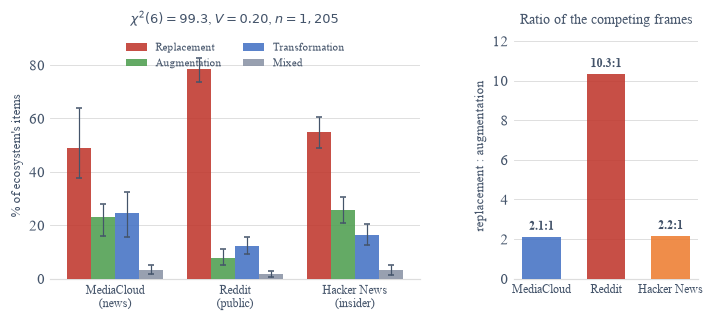

In [14]:
boot = A.cluster_boot_props(nt, "source", "coarse_frame", A.FRAME_ORDER, n_boot=2000)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 2.9),
                             gridspec_kw={"width_ratios": [2, 1], "wspace": .34})
w = .2
for k, f in enumerate(A.FRAME_ORDER):
    sub = boot[boot.coarse_frame == f].set_index("source").reindex(A.SRC_ORDER)
    x = np.arange(3) + (k - 1.5) * w
    a1.bar(x, sub.prop * 100, width=w, color=A.FRAME_COL[f], alpha=.88,
           label=A.FRAME_LAB[f], zorder=3)
    a1.errorbar(x, sub.prop * 100,
                yerr=[(sub.prop - sub.lo) * 100, (sub.hi - sub.prop) * 100],
                fmt="none", ecolor=A.NAVY, elinewidth=.8, capsize=1.8, zorder=4)
a1.set_xticks(range(3)); a1.set_xticklabels([A.SRC_LABEL[s] for s in A.SRC_ORDER], fontsize=7.6)
a1.set_ylabel("% of ecosystem's items", fontsize=8.5); a1.set_ylim(0, 92)
a1.legend(frameon=False, fontsize=7, ncol=2, loc="upper center")
a1.set_title(f"$\\chi^2(6)={r3['chi2']:.1f}$, $V={r3['V']:.2f}$, $n={r3['n']:,}$",
             fontsize=8.5, pad=6)
A.despine(a1)

rv = [ratio[s] for s in A.SRC_ORDER]
a2.bar(range(3), rv, color=[A.SRC_COL[s] for s in A.SRC_ORDER], alpha=.88, width=.6, zorder=3)
for i, v in enumerate(rv):
    a2.text(i, v + .35, f"{v:.1f}:1", ha="center", fontsize=8, fontweight="bold", color=A.NAVY)
a2.set_xticks(range(3)); a2.set_xticklabels([A.SRC_SHORT[s] for s in A.SRC_ORDER], fontsize=7.6)
a2.set_ylim(0, 12.4); a2.set_ylabel("replacement : augmentation", fontsize=8.5)
a2.set_title("Ratio of the competing frames", fontsize=9, pad=6)
A.despine(a2)
fig.savefig(FIG / "fig5_rq3_ecosystem.pdf", bbox_inches="tight"); plt.show()

The pattern is not a three-way divergence. It is a split between the public and
the two expert-adjacent sources.
News and the technology forum sit at 2.1:1 and 2.2:1; Reddit at 10.3:1. The
Holm-corrected pairwise tests confirm it: both Reddit contrasts are large
(V = 0.31, 0.28) while news vs Hacker News is marginal (V = 0.10).

Two things stand out in the figure. MediaCloud's intervals are the **widest**
despite it having the largest analytic n. This is the correct behaviour, because
news items
concentrate within fewer outlets, so the effective number of independent
observations is lower than the item count implies. And the length-split V values
(0.262, 0.276) are *larger* than the pooled 0.203, so length differences suppress
rather than manufacture the effect.

## 6. RQ4: temporal dynamics (Table 6, Figure 6)

In [15]:
pooled = A.trend(nt, "Pooled")
per = [A.trend(nt[nt.source == s], A.SRC_SHORT[s]) for s in A.SRC_ORDER]
ph = multipletests([r["p"] for r in per], method="holm")[1]
for r, p in zip(per, ph):
    r["p_holm"] = p

tab6 = pd.DataFrame([pooled] + per)
tab6["95% CI"] = tab6.apply(lambda r: f"[{r.lo:.2f}, {r.hi:.2f}]", axis=1)
display(tab6[["subset", "n", "OR", "95% CI", "p", "p_holm"]].round(
    {"OR": 3, "p": 4, "p_holm": 4}).set_index("subset"))

inter = smf.logit("is_repl ~ t_years * C(source)", data=nt).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": nt.cluster})
p_int = min(v for k, v in inter.pvalues.items() if "t_years:" in k)
print(f"time x ecosystem interaction: min p = {p_int:.4f}")

RESULTS.update({"rq4_pooled_OR": round(pooled["OR"], 3), "rq4_pooled_p": round(pooled["p"], 3),
                "rq4_reddit_OR": round(per[1]["OR"], 3),
                "rq4_reddit_p_holm": round(per[1]["p_holm"], 4),
                "rq4_mc_OR": round(per[0]["OR"], 3), "rq4_hn_OR": round(per[2]["OR"], 3)})

,n,OR,95% CI,p,p_holm
subset,,,,,
Pooled,1205,1.078,"[0.96, 1.21]",0.2066,NaN
MediaCloud,446,0.982,"[0.81, 1.20]",0.8581,1.0000
Reddit,434,1.439,"[1.16, 1.79]",0.0011,0.0032
Hacker News,325,0.947,"[0.78, 1.15]",0.5900,1.0000


time x ecosystem interaction: min p = 0.0054


In [16]:
print("within Reddit, one frame replacing another rather than both rising:")
r = nt[nt.source == "reddit"].copy()
for f in A.FRAME_ORDER:
    r["y"] = (r.coarse_frame == f).astype(int)
    t = A.trend(r, f, outcome="y")
    print(f"  {A.FRAME_LAB[f]:15s} OR={t['OR']:.3f} [{t['lo']:.2f}, {t['hi']:.2f}] p={t['p']:.4f}")
    if f == "AUGMENTATION":
        RESULTS["rq4_reddit_aug_OR"] = round(t["OR"], 3)

top = r.subreddit.value_counts()
r["sub_c"] = r.subreddit.where(r.subreddit.isin(top[top >= 25].index), "OTHER")
adj = A.trend(r, "subreddit-adjusted", extra="+ C(sub_c)")
nb = A.trend(nt[(nt.source == "reddit") & (nt.in_neutral_baseline == True)], "frame-neutral")
print(f"\n  subreddit-adjusted   OR={adj['OR']:.3f} [{adj['lo']:.2f}, {adj['hi']:.2f}] p={adj['p']:.4f}")
print(f"  frame-neutral only   OR={nb['OR']:.3f} [{nb['lo']:.2f}, {nb['hi']:.2f}] p={nb['p']:.4f}")
RESULTS["rq4_reddit_adj_OR"] = round(adj["OR"], 3)

pre, post = nt[nt.date < A.GPT4_RELEASE], nt[nt.date >= A.GPT4_RELEASE]
_, p_gpt = proportions_ztest([pre.is_repl.sum(), post.is_repl.sum()], [len(pre), len(post)])
print(f"\npre-registered GPT-4 test: pre {pre.is_repl.mean()*100:.1f}% (n={len(pre)}) vs "
      f"post {post.is_repl.mean()*100:.1f}% (n={len(post)}), p={p_gpt:.3f}")
RESULTS["rq4_gpt4_p"] = round(p_gpt, 3)

within Reddit, one frame replacing another rather than both rising:
  Replacement     OR=1.439 [1.16, 1.79] p=0.0011
  Augmentation    OR=0.474 [0.31, 0.72] p=0.0005
  Transformation  OR=0.861 [0.67, 1.11] p=0.2485
  Mixed           OR=1.216 [0.74, 2.00] p=0.4418

  subreddit-adjusted   OR=1.412 [1.12, 1.79] p=0.0042
  frame-neutral only   OR=1.497 [1.13, 1.98] p=0.0049

pre-registered GPT-4 test: pre 66.9% (n=121) vs post 60.6% (n=1084), p=0.175


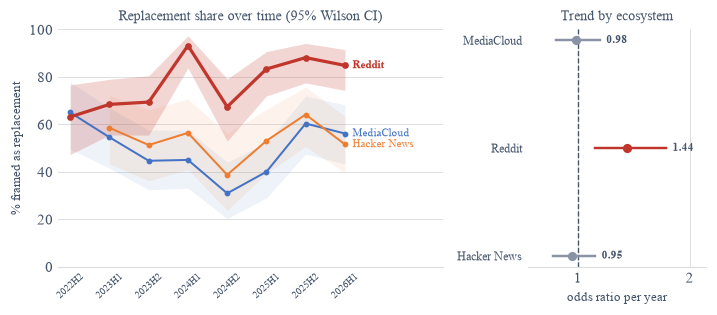

In [17]:
g = nt.groupby(["source", "half"]).is_repl.agg(["sum", "size"]).reset_index()
g["p"] = g["sum"] / g["size"] * 100
lo_, hi_ = A.wilson(g["sum"], g["size"])
g["lo"], g["hi"] = lo_ * 100, hi_ * 100
halves = sorted(nt.half.unique()); xi = {h: i for i, h in enumerate(halves)}
MIN_N = 20                      # a single point at n=9 reads as a trend it is not
g.loc[g["size"] < MIN_N, ["p", "lo", "hi"]] = np.nan

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 2.8),
                             gridspec_kw={"width_ratios": [2.15, 1], "wspace": .30})
for s in A.SRC_ORDER:
    d = g[g.source == s].set_index("half").reindex(halves)
    x = [xi[h] for h in halves]
    a1.fill_between(x, d.lo, d.hi, color=A.SRC_COL[s],
                    alpha=.20 if s == "reddit" else .09, lw=0)
    a1.plot(x, d.p, marker="o", ms=3.4 if s == "reddit" else 2.8, color=A.SRC_COL[s],
            lw=2.1 if s == "reddit" else 1.3, zorder=3 if s == "reddit" else 2)
    last = d.p.last_valid_index()
    a1.annotate(A.SRC_SHORT[s], xy=(xi[last], d.p.loc[last]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=7.2,
                color=A.SRC_COL[s], fontweight="bold" if s == "reddit" else "normal")
a1.set_xticks(list(xi.values())); a1.set_xticklabels(halves, fontsize=6.8, rotation=42)
a1.set_ylabel("% framed as replacement", fontsize=8.5); a1.set_ylim(0, 100)
a1.set_xlim(-.3, len(halves) - 1 + 2.5)
a1.set_title("Replacement share over time (95% Wilson CI)", fontsize=9, pad=6)
A.despine(a1)

yv = np.arange(len(per))[::-1]
for i, rr in enumerate(per):
    col = A.RED if rr["p_holm"] < .05 else A.MUTED
    a2.plot([rr["lo"], rr["hi"]], [yv[i], yv[i]], color=col, lw=1.6, zorder=3)
    a2.plot(rr["OR"], yv[i], "o", ms=5, color=col, zorder=4)
    a2.text(rr["hi"] + .06, yv[i], f"{rr['OR']:.2f}", va="center", fontsize=7.5,
            fontweight="bold", color=A.NAVY)
a2.axvline(1.0, color=A.NAVY, ls="--", lw=.9)
a2.set_yticks(yv); a2.set_yticklabels([r["subset"] for r in per], fontsize=7.6)
a2.set_xlim(.55, 2.15); a2.set_xlabel("odds ratio per year", fontsize=8.5)
a2.set_title("Trend by ecosystem", fontsize=9, pad=6)
A.despine(a2, grid_axis="x")
fig.savefig(FIG / "fig6_rq4_temporal.pdf", bbox_inches="tight"); plt.show()

Pooled, RQ4 is null (OR 1.078, p = 0.207) and the pre-registered GPT-4 test is
null (p = 0.175). Disaggregated, Reddit rises at 1.44 per year (Holm p = 0.003)
while both expert-adjacent ecosystems are flat, and the interaction is
significant (p = 0.005), so the divergence is a tested effect and not an artefact
of splitting the sample.

One frame is displacing the other: augmentation falls at 0.474 per year, close to
the reciprocal of the replacement rise, while transformation and mixed are flat.
Adjusting for subreddit composition (1.412) rules out a changing community mix
manufacturing the trend.

## 7. Unsupervised triangulation (Figure 7)

Sentiment is computed on the same text unit the coder saw, so frame and valence
are measured on identical inputs.

In [18]:
import html, re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
_TAG, _WS = re.compile(r"<[^>]+>"), re.compile(r"\s+")

def unit(r):
    t = _WS.sub(" ", _TAG.sub(" ", html.unescape(str(r.title) if pd.notna(r.title) else ""))).strip()
    if r.source == "mediacloud":
        return t
    b = _WS.sub(" ", _TAG.sub(" ", html.unescape(str(r.text)))).strip() if pd.notna(r.text) else ""
    return (t + " " + " ".join(b.split()[:100])).strip()

sia = SentimentIntensityAnalyzer()
nt["compound"] = nt.apply(unit, axis=1).apply(lambda t: sia.polarity_scores(t)["compound"])

by_frame = nt.groupby("coarse_frame").compound.agg(["count", "median", "mean"]).reindex(A.FRAME_ORDER)
H, p = kruskal(*[nt[nt.coarse_frame == f].compound.values for f in A.FRAME_ORDER])
display(by_frame.round(3))
print(f"Kruskal-Wallis across frames: H = {H:.1f}, p = {p:.2e}")
print("(non-parametric because VADER scores are bounded and zero-inflated, so ANOVA fails)")

Hs, ps = kruskal(*[nt[nt.source == s].compound.values for s in A.SRC_ORDER])
print(f"\nacross ecosystems, same {len(nt):,} items: H = {Hs:.1f}, p = {ps:.3f}")
for s in A.SRC_ORDER:
    d = nt[nt.source == s]
    print(f"  {A.SRC_SHORT[s]:12s} median {d.compound.median():+.3f}  "
          f"mean {d.compound.mean():+.3f}  replacement {(d.coarse_frame=='REPLACEMENT').mean()*100:.1f}%")
RESULTS["sentiment_H_frame"] = round(H, 1)

,count,median,mean
coarse_frame,,,
REPLACEMENT,738,0.000,-0.014
AUGMENTATION,219,0.382,0.309
TRANSFORMATION,216,0.000,0.104
MIXED,32,0.000,0.049


Kruskal-Wallis across frames: H = 77.9, p = 8.60e-17
(non-parametric because VADER scores are bounded and zero-inflated, so ANOVA fails)

across ecosystems, same 1,205 items: H = 8.4, p = 0.015
  MediaCloud   median +0.000  mean +0.040  replacement 48.9%
  Reddit       median +0.000  mean +0.041  replacement 78.6%
  Hacker News  median +0.000  mean +0.142  replacement 55.1%


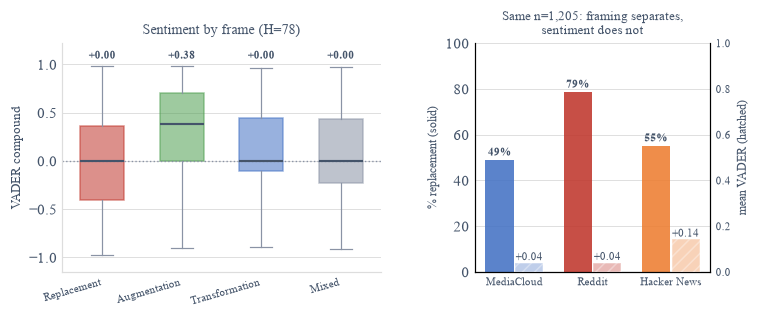

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 2.7),
                             gridspec_kw={"width_ratios": [1.35, 1], "wspace": .34})
bp = a1.boxplot([nt[nt.coarse_frame == f].compound.values for f in A.FRAME_ORDER],
                widths=.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=A.NAVY, lw=1.4),
                whiskerprops=dict(color=A.MUTED, lw=.8), capprops=dict(color=A.MUTED, lw=.8))
for patch, f in zip(bp["boxes"], A.FRAME_ORDER):
    patch.set_facecolor(A.FRAME_COL[f]); patch.set_alpha(.55); patch.set_edgecolor(A.FRAME_COL[f])
a1.axhline(0, color=A.MUTED, ls=":", lw=.9)
for i, f in enumerate(A.FRAME_ORDER):
    a1.text(i + 1, 1.06, f"{by_frame.loc[f,'median']:+.2f}", ha="center",
            fontsize=7, fontweight="bold", color=A.NAVY)
a1.set_xticks(range(1, 5))
a1.set_xticklabels([A.FRAME_LAB[f] for f in A.FRAME_ORDER], fontsize=7.2, rotation=16, ha="right")
a1.set_ylabel("VADER compound", fontsize=8.5); a1.set_ylim(-1.15, 1.22)
a1.set_title(f"Sentiment by frame (H={H:.0f})", fontsize=9, pad=6)
A.despine(a1, keep=("left", "bottom"))

x = np.arange(3)
repl = [(nt[nt.source == s].coarse_frame == "REPLACEMENT").mean() * 100 for s in A.SRC_ORDER]
a2.bar(x - .19, repl, width=.36, color=[A.SRC_COL[s] for s in A.SRC_ORDER], alpha=.88, zorder=3)
for i, v in enumerate(repl):
    a2.text(x[i] - .19, v + 2, f"{v:.0f}%", ha="center", fontsize=7, fontweight="bold", color=A.NAVY)
a2b = a2.twinx()
means = [nt[nt.source == s].compound.mean() for s in A.SRC_ORDER]
a2b.bar(x + .19, means, width=.36, color=[A.SRC_COL[s] for s in A.SRC_ORDER],
        alpha=.34, hatch="///", edgecolor="white", zorder=3)
for i, v in enumerate(means):
    a2b.text(x[i] + .19, v + .012, f"{v:+.2f}", ha="center", fontsize=7, color=A.NAVY)
a2.set_xticks(x); a2.set_xticklabels([A.SRC_SHORT[s] for s in A.SRC_ORDER], fontsize=7.2)
a2.set_ylim(0, 100); a2.set_ylabel("% replacement (solid)", fontsize=8)
a2b.set_ylim(0, 1.0); a2b.set_ylabel("mean VADER (hatched)", fontsize=8)
a2b.tick_params(labelsize=7, length=0); a2b.spines["top"].set_visible(False)
a2.set_title(f"Same n={len(nt):,}: framing separates,\nsentiment does not", fontsize=8.5, pad=6)
A.despine(a2)
fig.savefig(FIG / "fig7_triangulation.pdf", bbox_inches="tight"); plt.show()

Sentiment differs significantly across frames (H = 77.9), and the ordering is as
predicted, but only augmentation has a non-zero median. Replacement-framed
text has a median of exactly 0.000: it is affectively *neutral*, not negative.
Text describing job displacement is largely flat, declarative prose carrying no
sentiment lexicon.

On the same 1,205 items, framing separates the ecosystems by nearly thirty
percentage points while sentiment barely distinguishes them (H = 8.4 against
77.9 across frames). An off-the-shelf sentiment score would have found almost
nothing here. That is the empirical case for theory-driven frame coding.

*Note:* the report's corpus-level sentiment description uses the full 40,732-item
corpus; the comparison above deliberately holds one population so that framing
and sentiment are measured on identical items.

## 8. Reproduction check

Every value published in the report, re-asserted against what this notebook just
computed. **If any assertion fails, the report and the data have diverged.**

In [20]:
PUBLISHED = {
    "n_raw": 328_270, "n_clean": 40_735, "n_coded": 1_800, "n_analytic": 1_205,
    "n_validation": 300, "n_functions_passing": 3,
    "kappa_frame": 0.797, "kappa_treatment": 0.591, "agree_treatment": 0.877,
    "rq1_replacement": 61.2, "rq1_augmentation": 18.2,
    "rq1_transformation": 17.9, "rq1_mixed": 2.7, "tangential_hn": 45.8,
    "rq2_V_problem": 0.580, "rq2_V_cause": 0.193,
    "repl_treatment_none": 81.6, "repl_cause_none": 1.8,
    "rq3_chi2": 99.3, "rq3_V": 0.203, "rq3_dof": 6, "rq3_n": 1_205,
    "rq3_V_neutral": 0.207,
    "ratio_mediacloud": 2.1, "ratio_reddit": 10.3, "ratio_hackernews": 2.2,
    "rq4_pooled_OR": 1.078, "rq4_pooled_p": 0.207,
    "rq4_reddit_OR": 1.439, "rq4_reddit_p_holm": 0.0032,
    "rq4_mc_OR": 0.982, "rq4_hn_OR": 0.947,
    "rq4_reddit_aug_OR": 0.474, "rq4_reddit_adj_OR": 1.412,
    "rq4_gpt4_p": 0.175, "sentiment_H_frame": 77.9,
}

fails = []
print(f"{'value':26s} {'report':>10s} {'notebook':>10s}   ok")
for k, want in PUBLISHED.items():
    got = RESULTS.get(k)
    if got is None:
        fails.append((k, want, "MISSING")); ok = False
    else:
        ok = abs(float(got) - float(want)) <= (0.0011 if abs(want) < 1 else 0.06)
        if not ok:
            fails.append((k, want, got))
    print(f"{k:26s} {want:>10} {str(got):>10s}   {'OK' if ok else 'FAIL'}")

print(f"\n{len(PUBLISHED) - len(fails)}/{len(PUBLISHED)} published values reproduced")
assert not fails, f"REPORT AND DATA HAVE DIVERGED: {fails}"
print("All values in the submitted report reproduce from the data in this folder.")

value                          report   notebook   ok
n_raw                          328270     328270   OK
n_clean                         40735      40735   OK
n_coded                          1800       1800   OK
n_analytic                       1205       1205   OK
n_validation                      300        300   OK
n_functions_passing                 3          3   OK
kappa_frame                     0.797      0.797   OK
kappa_treatment                 0.591      0.591   OK
agree_treatment                 0.877      0.877   OK
rq1_replacement                  61.2       61.2   OK
rq1_augmentation                 18.2       18.2   OK
rq1_transformation               17.9       17.9   OK
rq1_mixed                         2.7        2.7   OK
tangential_hn                    45.8       45.8   OK
rq2_V_problem                    0.58       0.58   OK
rq2_V_cause                     0.193      0.193   OK
repl_treatment_none              81.6       81.6   OK
repl_cause_none             